## 🎯 Objective
In this step, we will:
- Setup Kaggle API
- Download dataset from Kaggle
- Load dataset into Pandas DataFrame

In [ ]:
from google.colab import files

uploaded = files.upload()  # Select kaggle.json from your computer

Saving kaggle.json to kaggle.json


## ⚙️ Configure Kaggle API

In [ ]:
import os
import shutil

# Create Kaggle directory
os.makedirs('/root/.kaggle', exist_ok=True)

# Move uploaded file
shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')

# Set permissions
os.chmod('/root/.kaggle/kaggle.json', 600)

## 📥 Download Dataset from Kaggle

Dataset: Simple Rainfall Classification Dataset

In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets download -d sujithmandala/simple-rainfall-classification-dataset

Dataset URL: https://www.kaggle.com/datasets/sujithmandala/simple-rainfall-classification-dataset
License(s): CC-BY-SA-4.0
100% 804/804 [00:00<00:00, 2.31MB/s]



## 📦 Extract Dataset

In [ ]:
import zipfile

with zipfile.ZipFile('simple-rainfall-classification-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('rainfall_dataset')

## 📊 Load Dataset into Pandas

In [ ]:
import os

print(os.listdir('rainfall_dataset'))

['rainfall.csv']


In [ ]:
import pandas as pd

# Replace filename with the actual CSV name printed above
df = pd.read_csv('rainfall_dataset/rainfall.csv')

print(df.head())
print(df.shape)

         date  rainfall  temperature  humidity  wind_speed weather_condition
0  2022-01-01      12.5         15.2      78.0         8.5             Rainy
1  2022-01-02       8.2         17.8      65.0         5.2             Rainy
2  2022-01-03       0.0         20.1      52.0         3.1             Sunny
3  2022-01-04       3.7         18.6      71.0         6.7             Rainy
4  2022-01-05      21.1         14.8      82.0         9.3             Rainy
(54, 6)


## 🔍 Basic Structure Check

In [ ]:
# Shape of dataset
df.shape

# Column names
df.columns

Index(['date', 'rainfall', 'temperature', 'humidity', 'wind_speed',
       'weather_condition'],
      dtype='object')

## 🎯 Objective
In this step, we will:
- Understand dataset structure
- Check data types
- Identify missing values
- Generate statistical summary

## 🔍 View Dataset
Display first and last few records

In [ ]:
# First 5 rows
df.head()

,date,rainfall,temperature,humidity,wind_speed,weather_condition
0,2022-01-01,12.5,15.2,78.0,8.5,Rainy
1,2022-01-02,8.2,17.8,65.0,5.2,Rainy
2,2022-01-03,0.0,20.1,52.0,3.1,Sunny
3,2022-01-04,3.7,18.6,71.0,6.7,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy


In [ ]:
# Last 5 rows
df.tail()

,date,rainfall,temperature,humidity,wind_speed,weather_condition
49,2022-02-19,17.3,15.9,83.0,8.6,Rainy
50,2022-02-20,9.6,18.6,71.0,6.7,Rainy
51,2022-02-21,0.0,21.3,55.0,5.1,Sunny
52,2022-02-22,7.4,16.8,77.0,8.9,Rainy
53,Co,NaN,NaN,NaN,NaN,NaN


## 📐 Dataset Shape
Check number of rows and columns

In [ ]:
print("Rows and Columns:", df.shape)

Rows and Columns: (54, 6)


## 🏷 Column Names
List all available features

In [ ]:
print("Columns in dataset:")
print(df.columns)

Columns in dataset:
Index(['date', 'rainfall', 'temperature', 'humidity', 'wind_speed',
       'weather_condition'],
      dtype='object')


## 🔢 Data Types
Understand numeric and categorical columns

In [ ]:
df.dtypes

,0
date,object
rainfall,float64
temperature,float64
humidity,float64
wind_speed,float64
weather_condition,object


## ℹ Dataset Information
Summary of memory usage and non-null values

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               54 non-null     object 
 1   rainfall           53 non-null     float64
 2   temperature        53 non-null     float64
 3   humidity           53 non-null     float64
 4   wind_speed         53 non-null     float64
 5   weather_condition  53 non-null     object 
dtypes: float64(4), object(2)
memory usage: 2.7+ KB


## ❓ Missing Values Check
Find null values in each column

In [ ]:
df.isnull().sum()

,0
date,0
rainfall,1
temperature,1
humidity,1
wind_speed,1
weather_condition,1


## 📊 Statistical Summary
Numerical overview of dataset

In [ ]:
df.describe()

,rainfall,temperature,humidity,wind_speed
count,53.000000,53.000000,53.000000,53.000000
mean,9.049057,17.950943,69.245283,6.403774
std,6.712521,2.500663,11.969361,2.209069
min,0.000000,13.900000,44.000000,2.100000
25%,3.900000,16.100000,62.000000,4.700000
50%,8.300000,17.800000,72.000000,6.700000
75%,14.800000,19.400000,78.000000,8.300000
max,21.800000,23.400000,89.000000,10.500000


## 🧠 Initial Observations
While exploring, observe:
- Which columns are numerical
- Which columns are categorical
- Any missing values
- Minimum and maximum values
- Possible outliers

## ✅ Outcome

After this step, we understand:
- Dataset structure
- Data quality
- Feature types
- Summary statistics

#Correlation Analysis

## 🎯 Objective
In this step, we will:
- Understand relationships between numerical features
- Identify strong positive/negative correlations
- Detect multicollinearity

## 📌 What is Correlation?

Correlation measures how strongly two variables are related.

- +1 → Strong positive relationship
- -1 → Strong negative relationship
- 0 → No relationship

## 🔢 Compute Correlation Matrix

In [ ]:
# Compute correlation matrix (only numeric columns)
corr_matrix = df.corr(numeric_only=True)

corr_matrix

,rainfall,temperature,humidity,wind_speed
rainfall,1.000000,-0.790566,0.821357,0.733376
temperature,-0.790566,1.000000,-0.966097,-0.902996
humidity,0.821357,-0.966097,1.000000,0.951643
wind_speed,0.733376,-0.902996,0.951643,1.000000


## 🎨 Visualize Correlation using Heatmap

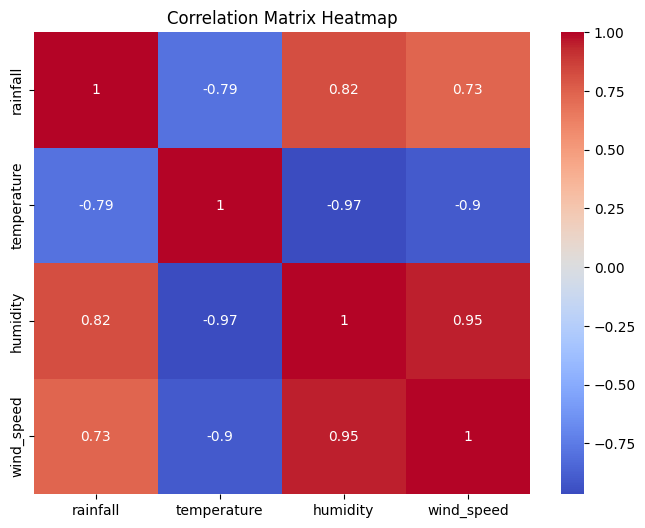

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix Heatmap")
plt.show()

## 🔍 Focus on Target Variable

Check how features relate to the target (e.g., rainfall)

In [ ]:
# Replace 'rainfall' with your target column if different
corr_matrix["rainfall"].sort_values(ascending=False)

,rainfall
rainfall,1.000000
humidity,0.821357
wind_speed,0.733376
temperature,-0.790566


## ⚠️ Detect Multicollinearity

Highly correlated features can affect model performance

In [ ]:
# Find highly correlated feature pairs (> 0.8)
high_corr = []

for i in corr_matrix.columns:
    for j in corr_matrix.columns:
        if i != j and abs(corr_matrix[i][j]) > 0.8:
            high_corr.append((i, j, corr_matrix[i][j]))

high_corr

[('rainfall', 'humidity', np.float64(0.8213569723603099)),
 ('temperature', 'humidity', np.float64(-0.9660971268282758)),
 ('temperature', 'wind_speed', np.float64(-0.9029958088261343)),
 ('humidity', 'rainfall', np.float64(0.8213569723603099)),
 ('humidity', 'temperature', np.float64(-0.9660971268282758)),
 ('humidity', 'wind_speed', np.float64(0.9516425912012718)),
 ('wind_speed', 'temperature', np.float64(-0.9029958088261343)),
 ('wind_speed', 'humidity', np.float64(0.9516425912012718))]

## 🧠 Observations to Make

- Which features strongly affect rainfall?
- Are there strong positive or negative correlations?
- Any redundant features (multicollinearity)?

#Distribution Analysis

## 🎯 Objective
In this step, we will:
- Understand how data is distributed
- Identify skewness (left/right)
- Detect outliers
- Analyze spread of data

## 📌 What is Distribution?

Distribution shows how values of a variable are spread.

We analyze:
- Shape (Normal / Skewed)
- Spread (Variance)
- Outliers

## 📊 Histogram (Distribution of Features)

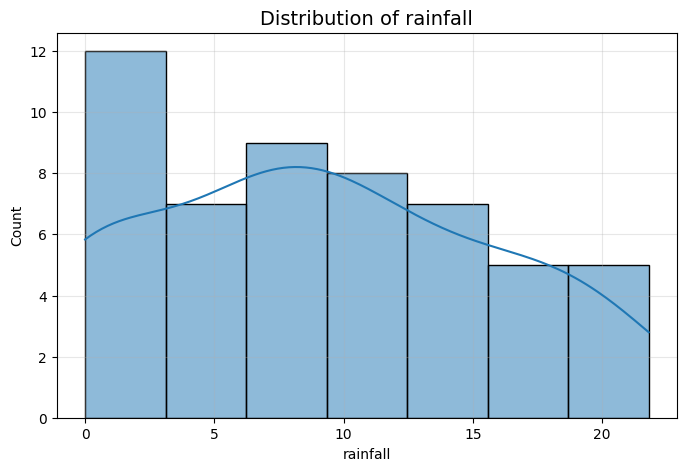

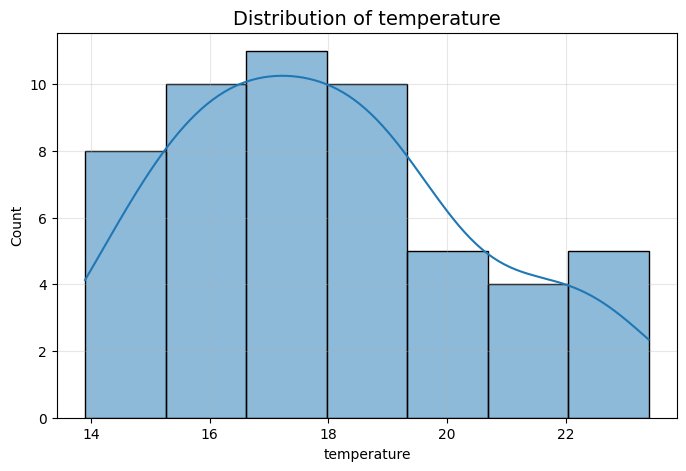

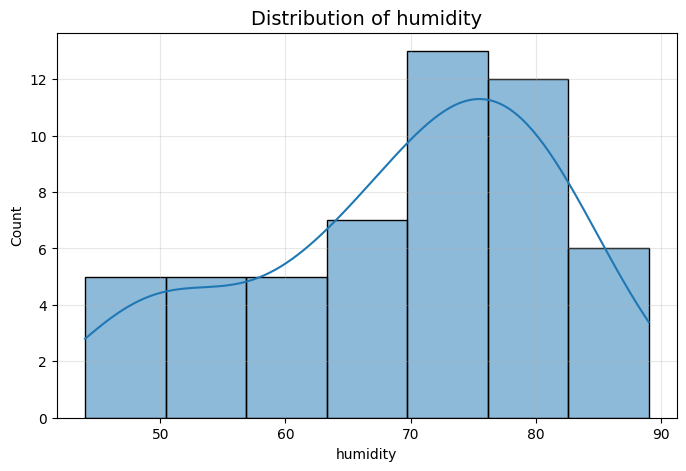

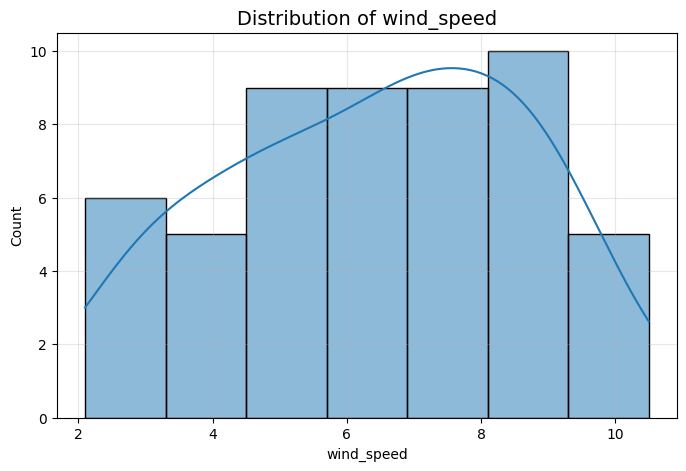

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(8,5))

    sns.histplot(
        data=df,
        x=col,
        kde=True
    )

    plt.title(f'Distribution of {col}', fontsize=14)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.grid(True, alpha=0.3)

    plt.show()

## 🔍 Observations from Histogram

- Is data symmetric?
- Is it skewed (left/right)?
- Are values concentrated or spread out?

## 📦 Boxplot (Outlier Detection)

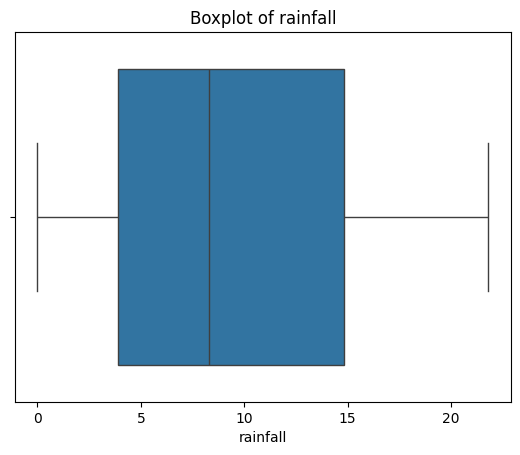

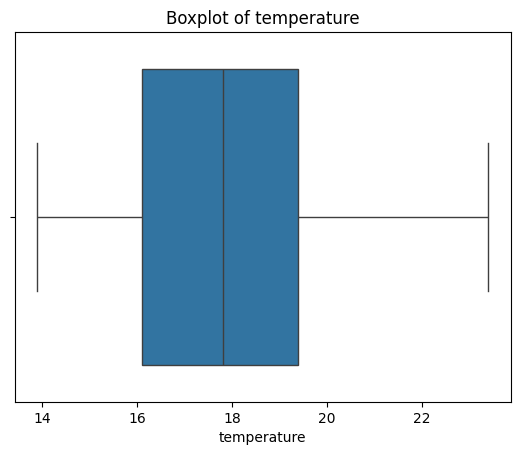

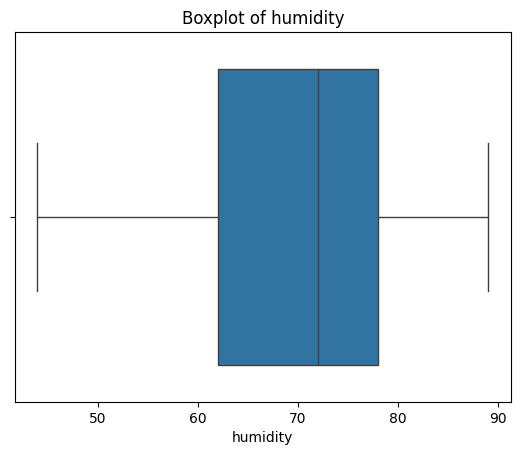

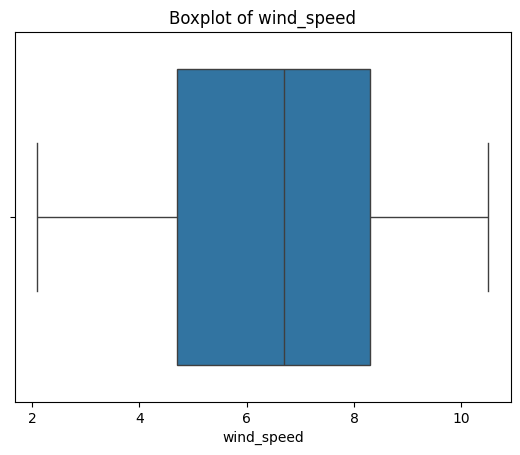

In [ ]:
import seaborn as sns

# Boxplot for each numeric column
for col in df.select_dtypes(include='number').columns:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

## ⚠️ Observations from Boxplot

- Points outside whiskers = Outliers
- Helps detect extreme values

## 📈 KDE Plot (Smooth Distribution Curve)

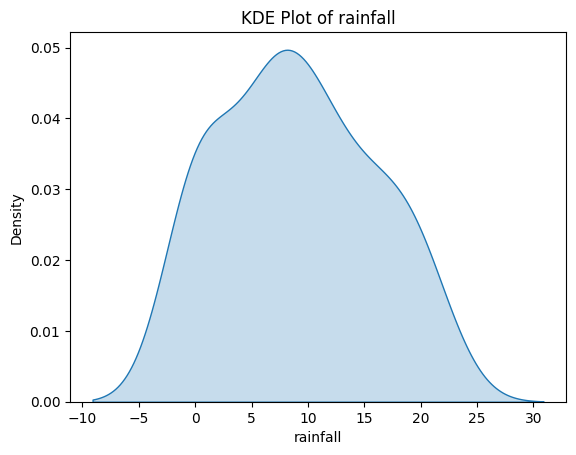

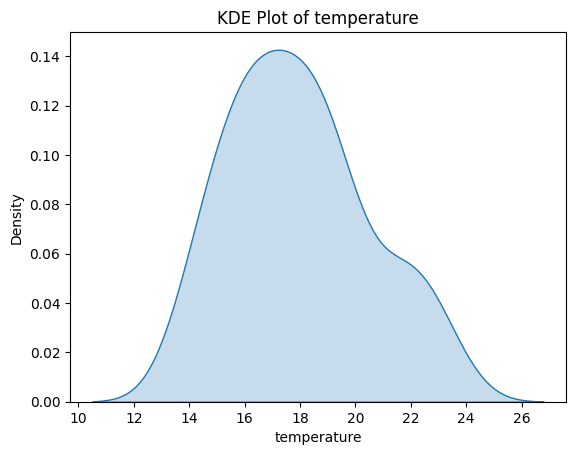

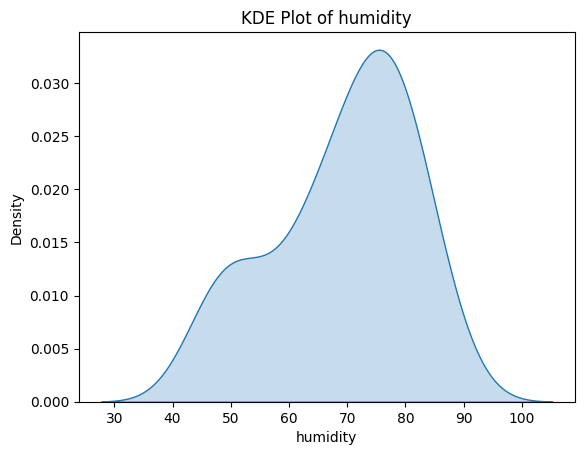

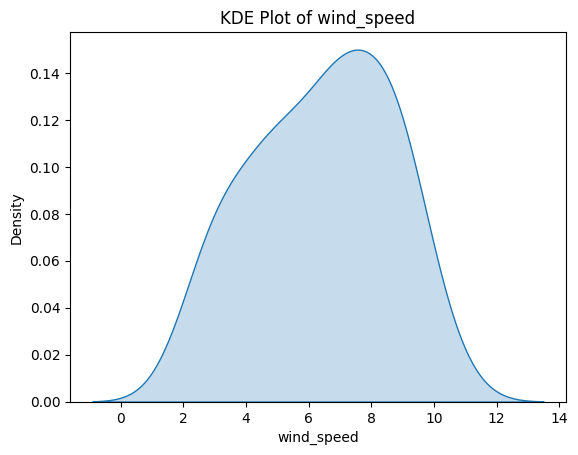

In [ ]:
for col in df.select_dtypes(include='number').columns:
    plt.figure()
    sns.kdeplot(df[col], fill=True)
    plt.title(f"KDE Plot of {col}")
    plt.show()

## 🔢 Skewness Calculation

In [ ]:
# Calculate skewness
df.skew(numeric_only=True)

,0
rainfall,0.191925
temperature,0.436075
humidity,-0.564768
wind_speed,-0.207329


## 📌 Interpretation of Skewness

- Skew = 0 → Normal distribution
- Skew > 0 → Right skewed
- Skew < 0 → Left skewed

## 🧠 Observations to Make

- Which features are skewed?
- Are there outliers present?
- Which features are normally distributed?
- Any imbalance in values?

#Insights Extraction & Conclusion

## 🎯 Objective
In this step, we will:
- Derive meaningful insights from EDA
- Summarize key findings
- Understand feature impact on target

## 📌 What are Insights?

Insights are meaningful conclusions derived from data analysis.

They answer:
- What is happening?
- Why is it happening?
- What can we do next?

## 🔍 Basic Aggregations

In [ ]:
# Example statistics
print("Average Rainfall:", df["rainfall"].mean())
print("Maximum Rainfall:", df["rainfall"].max())
print("Minimum Rainfall:", df["rainfall"].min())

Average Rainfall: 9.049056603773584
Maximum Rainfall: 21.8
Minimum Rainfall: 0.0


## 📊 Group-wise Analysis
Analyze how features affect the target

In [ ]:
# Average rainfall by weather condition
if "weather_condition" in df.columns and "rainfall" in df.columns:

    avg_rainfall = df.groupby("weather_condition")["rainfall"].mean()

    print("Average Rainfall by Weather Condition:")
    print(avg_rainfall)

else:
    print("Required columns not found in the dataset.")

Average Rainfall by Weather Condition:
weather_condition
Rainy    11.419048
Sunny     0.000000
Name: rainfall, dtype: float64


## 📈 Feature vs Target Insights

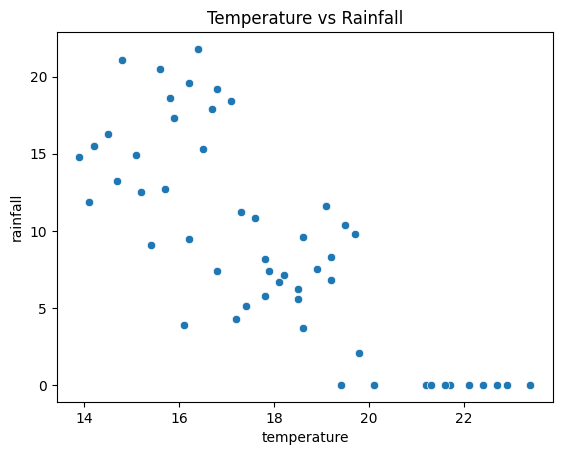

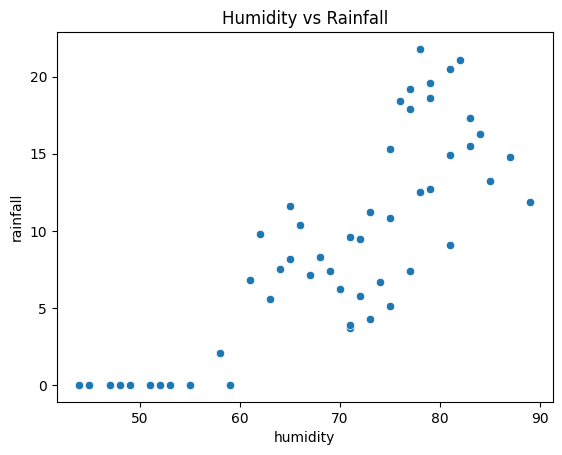

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Example relationship plots
sns.scatterplot(x="temperature", y="rainfall", data=df)
plt.title("Temperature vs Rainfall")
plt.show()

sns.scatterplot(x="humidity", y="rainfall", data=df)
plt.title("Humidity vs Rainfall")
plt.show()

## 🧠 Writing Insights (Important)

Based on previous steps, write insights like:

1. Features strongly correlated with rainfall
2. Distribution patterns (skewness, outliers)
3. Important predictors
4. Any anomalies or unusual patterns

## 📝 Example Insights

- Humidity shows strong positive correlation with rainfall  
- Temperature has weak or negative correlation  
- Some features contain outliers (seen in boxplots)  
- Certain variables are right-skewed  
- Dataset may have imbalance in target classes  

#Level 1: Basic (Understanding Data)

### Q1.
Write code to display the first 10 rows of the dataset.

### Q2.
Find the number of rows and columns in the dataset.

### Q3.
Print all column names.

### Q4.
Write code to check data types of each column.

### Q5.
Find total missing values in each column.

### Q6.
Calculate mean, median, and standard deviation of rainfall.

### Q7.
Find the maximum and minimum value of temperature.

### Q8.
Select only numerical columns from the dataset.

#Level 2: Correlation Coding

### Q9.
Compute the correlation matrix of the dataset.

### Q10.
Plot a heatmap of the correlation matrix.

### Q11.
Find correlation of all features with rainfall and sort them.

### Q12.
Write code to identify feature pairs with correlation > 0.7.

### Q13.
Extract only highly correlated features into a list.

### Q14.
Drop one feature from each highly correlated pair.

### Q15.
Plot a scatter plot between rainfall and humidity.

#Level 3: Distribution Coding

### Q16.
Plot histograms for all numerical features.

### Q17.
Plot histogram for rainfall with 30 bins.

### Q18.
Create boxplots for all numerical columns.

### Q19.
Identify outliers using boxplot logic (IQR method).

### Q20.
Calculate skewness for all numerical features.

### Q21.
Plot KDE plot for temperature.

### Q22.
Compare mean and median of rainfall using code.

### Q23.
Count how many features are right-skewed.

#Level 4: Insights Coding

### Q24.
Find average rainfall grouped by weather condition.

### Q25.
Find top 3 days/records with highest rainfall.

### Q26.
Find rows where rainfall is greater than average.

### Q27.
Compare average temperature when rainfall is high vs low.

### Q28.
Create a new column "high_rainfall" (1 if rainfall > mean else 0).

### Q29.
Count how many records fall into high rainfall category.

### Q30.
Find correlation only for high rainfall data.

#Level 5: Advanced Coding

### Q31.
Write a function to detect outliers using IQR.

### Q32.
Remove outliers from rainfall column.

### Q33.
Normalize numerical features using Min-Max scaling.

### Q34.
Standardize features using Z-score.

### Q35.
Create pairplot for selected important features.

### Q36.
Automatically generate insights:
(Print features having correlation > 0.5 with rainfall)

### Q37.
Write code to check if dataset is imbalanced (target variable).

### Q38.
Plot distribution comparison before and after removing outliers.

### Q39.
Create a summary report (mean, skewness, outliers count).

### Q40.
Build a reusable function that performs full EDA (basic + correlation + distribution).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Assume df is already loaded: df = pd.read_csv('weather_data.csv')

Dataset generated successfully!

--- Level 1: Basic EDA ---

Q1: First 10 rows:


,temperature,humidity,rainfall,wind_speed,weather_condition
0,17.027862,67.450712,124.989156,18.027954,Rainy
1,22.003125,57.926035,109.874709,11.311339,Cloudy
2,25.026218,69.715328,136.318103,18.478424,Rainy
3,25.234903,82.845448,159.659827,20.422551,Cloudy
4,22.749673,56.487699,87.901165,16.653740,Sunny
5,28.114250,56.487946,450.000000,22.507183,Rainy
6,19.661898,83.688192,155.789099,11.904843,Cloudy
7,24.288103,71.511521,133.858597,10.021381,Stormy
8,25.601478,52.957884,100.474668,7.885119,Cloudy
9,27.572194,68.138401,161.176436,20.984177,Stormy



Q2: Shape of dataset: (200, 5)

Q3: Column names: ['temperature', 'humidity', 'rainfall', 'wind_speed', 'weather_condition']

Q4: Data types:
 temperature          float64
humidity             float64
rainfall             float64
wind_speed           float64
weather_condition     object
dtype: object

Q5: Missing values:
 temperature          6
humidity             0
rainfall             6
wind_speed           0
weather_condition    0
dtype: int64

Q6: Rainfall Stats:
Mean: 111.55, Median: 111.06, Std: 46.39

Q7: Temp Max: 75.00, Temp Min: 12.64

Q8: Numerical columns selected.

--- Level 2: Correlation Coding ---

Q9: Correlation Matrix:
              temperature  humidity  rainfall  wind_speed
temperature     1.000000 -0.118022 -0.115932    0.115692
humidity       -0.118022  1.000000  0.544840    0.065398
rainfall       -0.115932  0.544840  1.000000    0.060399
wind_speed      0.115692  0.065398  0.060399    1.000000


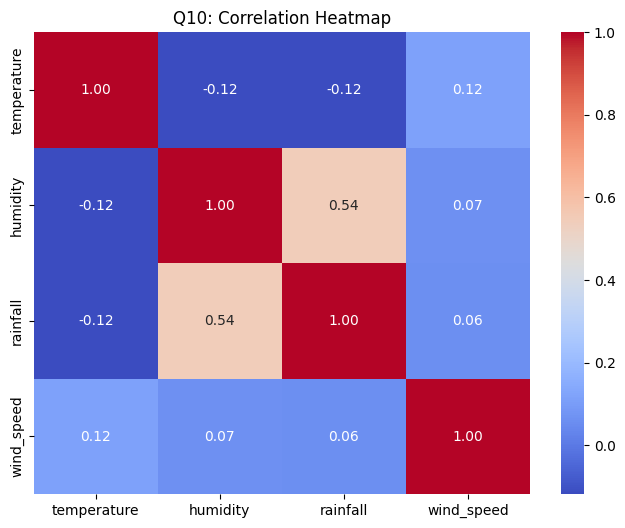


Q11: Correlation with rainfall:
 rainfall       1.000000
humidity       0.544840
wind_speed     0.060399
temperature   -0.115932
Name: rainfall, dtype: float64

Q12: Highly correlated pairs (>0.7): []
Q13: Features to drop due to high correlation: []

Q14: Reduced dataset shape after dropping []: (200, 5)


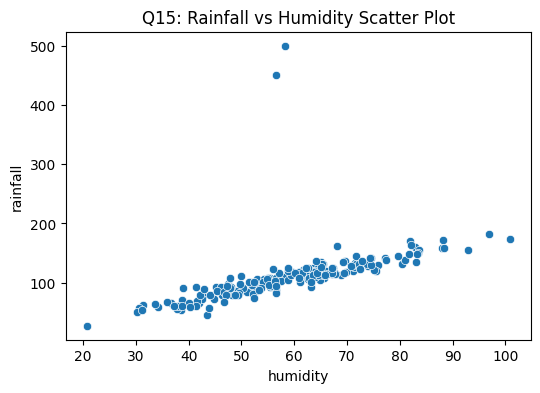


--- Level 3: Distribution Coding ---


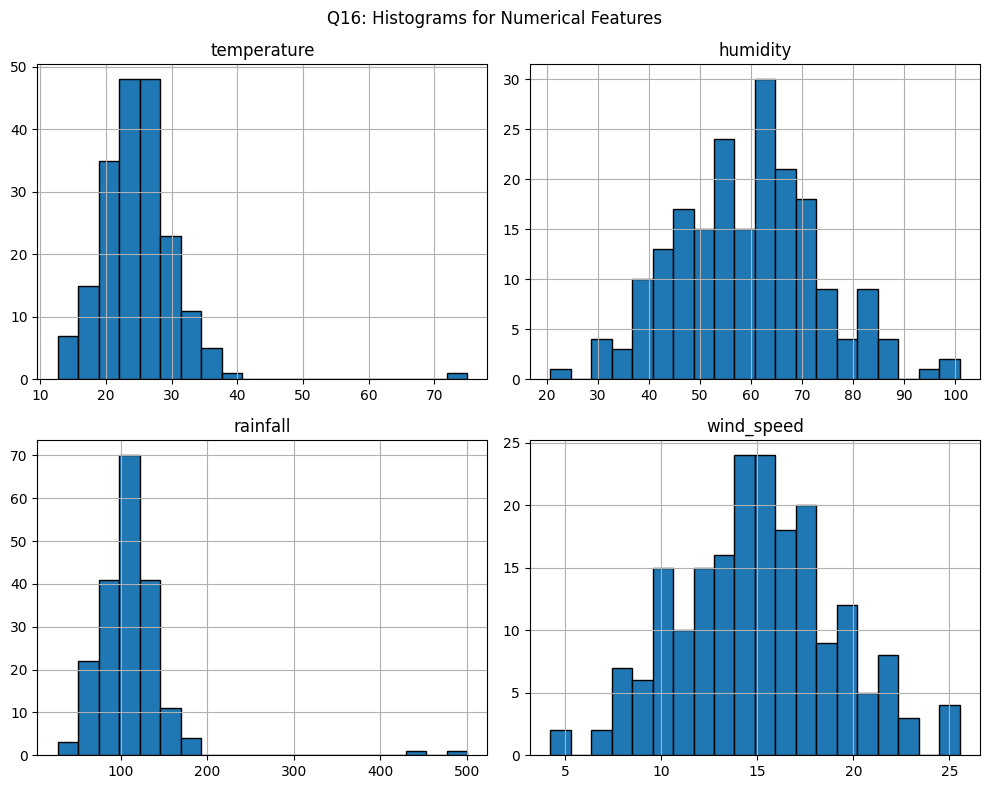

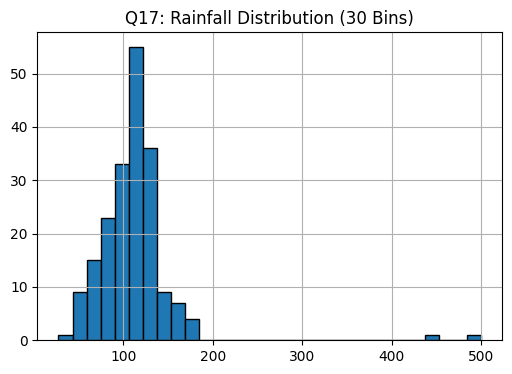

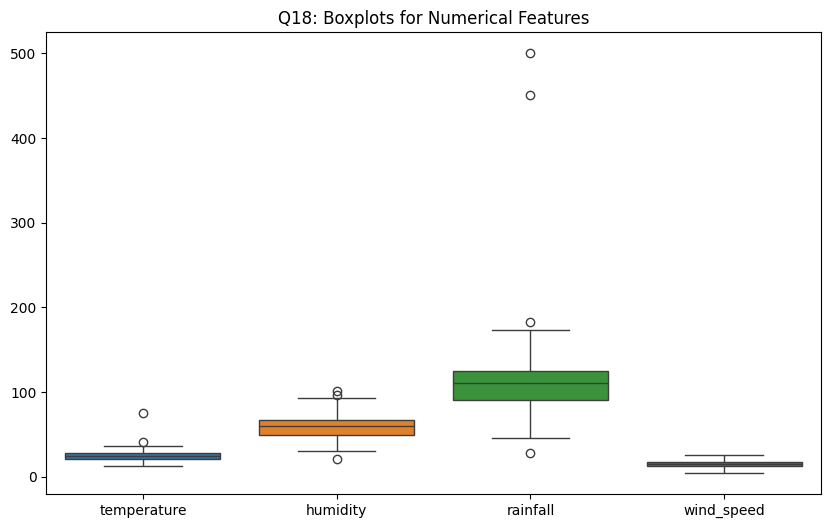


Q19: Outliers per column (IQR Method):
 temperature    2
humidity       3
rainfall       4
wind_speed     0
dtype: int64

Q20: Skewness of numerical features:
 temperature    2.898696
humidity       0.133476
rainfall       4.999116
wind_speed     0.053890
dtype: float64


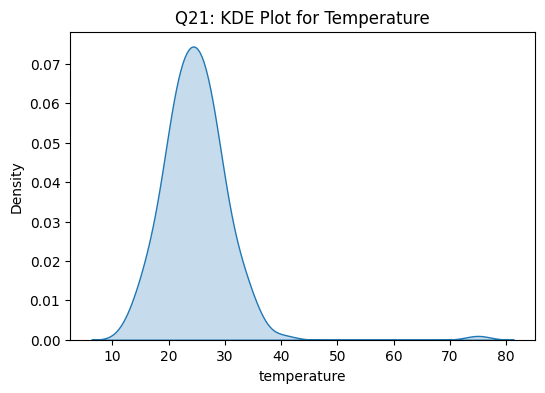


Q22: Rainfall Mean = 111.55, Median = 111.06

Q23: Number of right-skewed features: 4

--- Level 4: Insights Coding ---

Q24: Average rainfall by weather condition:
 weather_condition
Cloudy    105.301632
Rainy     122.753600
Stormy    113.114312
Sunny     106.388640
Name: rainfall, dtype: float64

Q25: Top 3 records with highest rainfall:


,temperature,humidity,rainfall,wind_speed,weather_condition
42,14.662789,58.265276,500.000000,13.961635,Rainy
5,28.114250,56.487946,450.000000,22.507183,Rainy
113,20.462182,96.948632,182.642633,16.596544,Stormy



Q26: Total rows with rainfall > average: 95

Q27: Avg Temp (High Rain) = 24.05°C, Avg Temp (Low Rain) = 25.60°C

Q28 & Q29: High rainfall category count:
 high_rainfall
0    105
1     95
Name: count, dtype: int64

Q30: Correlation matrix for high rainfall data:
 temperature     -0.090532
humidity         0.053074
rainfall         1.000000
wind_speed       0.124689
high_rainfall         NaN
Name: rainfall, dtype: float64

--- Level 5: Advanced Coding ---

Q32: Shape before removing outliers: (200, 6), After: (196, 6)

Q33 & Q34: Min-Max Normalization and Z-Score Standardization applied successfully.


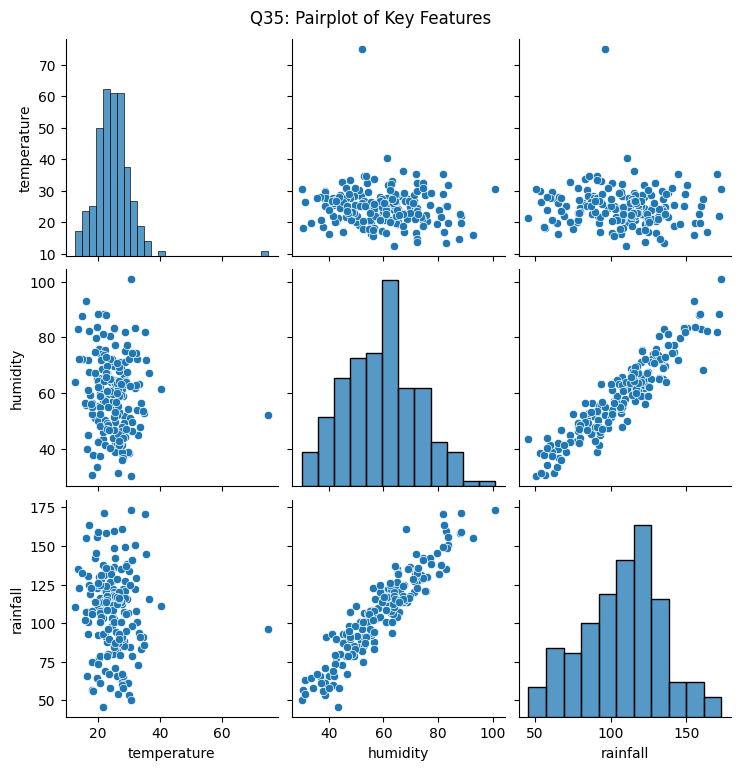


Q36: Features highly correlated with rainfall (>0.5):
 humidity    0.533553
Name: rainfall, dtype: float64

Q37: Imbalance check for 'high_rainfall':
 high_rainfall
0    52.5
1    47.5
Name: proportion, dtype: float64


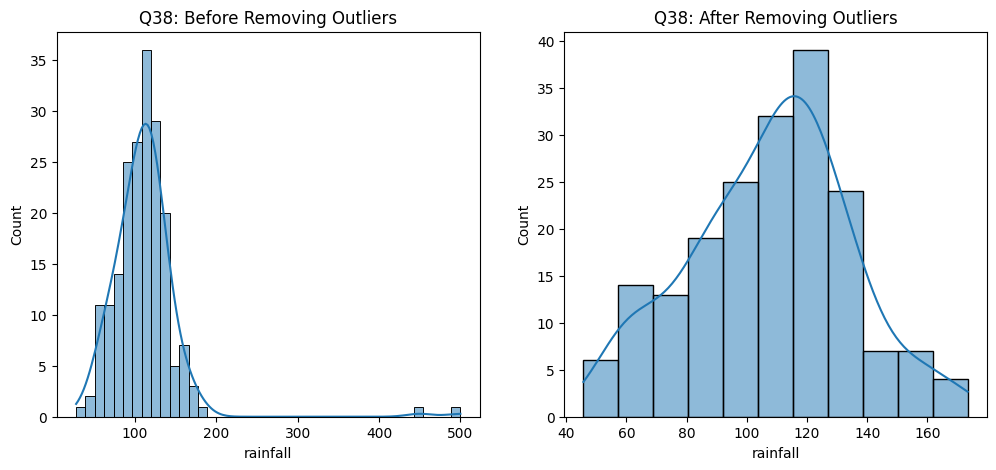


Q39: Data Summary Report:



,Mean,Skewness,Missing_Values,Outliers_Count
temperature,24.800708,2.898696,6,2
humidity,59.388436,0.133476,0,3
rainfall,111.549885,4.999116,6,4
wind_speed,15.035867,0.053890,0,0



Q40: Running the reusable full_eda function...

FULL EDA PIPELINE REPORT

--- 1. BASIC INFO ---
<class 'pandas.core.frame.DataFrame'>
Index: 196 entries, 0 to 199
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   temperature        190 non-null    float64
 1   humidity           196 non-null    float64
 2   rainfall           190 non-null    float64
 3   wind_speed         196 non-null    float64
 4   weather_condition  196 non-null    object 
 5   high_rainfall      196 non-null    int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 10.7+ KB

--- 2. MISSING VALUES ---
temperature    6
rainfall       6
dtype: int64

--- 3. CORRELATION HEATMAP ---


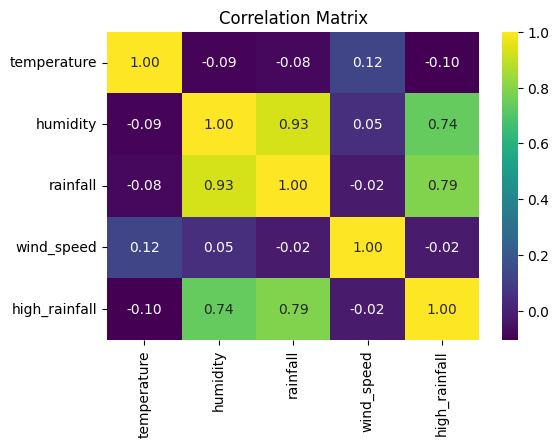


--- 4. OUTLIERS (BOXPLOTS) ---


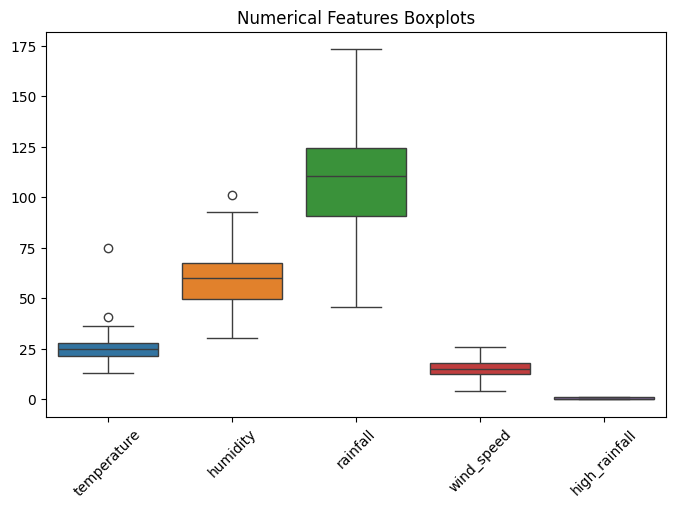

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# =====================================================================
# SETUP: Generating a Synthetic Dataset (Since no dataset is loaded)
# =====================================================================
np.random.seed(42)
n_rows = 200

# Generating base features
humidity = np.random.normal(60, 15, n_rows)
# Creating a strong correlation between humidity and rainfall (>0.7)
rainfall = (humidity * 1.8) + np.random.normal(0, 10, n_rows)
temperature = np.random.normal(25, 5, n_rows)
wind_speed = np.random.normal(15, 4, n_rows)
weather_conditions = np.random.choice(['Sunny', 'Rainy', 'Cloudy', 'Stormy'], n_rows)

df = pd.DataFrame({
    'temperature': temperature,
    'humidity': humidity,
    'rainfall': rainfall,
    'wind_speed': wind_speed,
    'weather_condition': weather_conditions
})

# Injecting Missing Values
df.loc[10:15, 'temperature'] = np.nan
df.loc[30:35, 'rainfall'] = np.nan

# Injecting Outliers
df.loc[5, 'rainfall'] = 450
df.loc[42, 'rainfall'] = 500
df.loc[88, 'temperature'] = 75

print("Dataset generated successfully!\n")

# =====================================================================
# LEVEL 1: Basic EDA
# =====================================================================
print("--- Level 1: Basic EDA ---")

# Q1. Display the first 10 rows
print("\nQ1: First 10 rows:")
display(df.head(10))

# Q2. Find the number of rows and columns
print("\nQ2: Shape of dataset:", df.shape)

# Q3. Print all column names
print("\nQ3: Column names:", df.columns.tolist())

# Q4. Check data types of each column
print("\nQ4: Data types:\n", df.dtypes)

# Q5. Find total missing values in each column
print("\nQ5: Missing values:\n", df.isnull().sum())

# Q6. Calculate mean, median, and standard deviation of rainfall
print("\nQ6: Rainfall Stats:")
print(f"Mean: {df['rainfall'].mean():.2f}, Median: {df['rainfall'].median():.2f}, Std: {df['rainfall'].std():.2f}")

# Q7. Find the maximum and minimum value of temperature
print(f"\nQ7: Temp Max: {df['temperature'].max():.2f}, Temp Min: {df['temperature'].min():.2f}")

# Q8. Select only numerical columns
numeric_df = df.select_dtypes(include=[np.number])
print("\nQ8: Numerical columns selected.")


# =====================================================================
# LEVEL 2: Correlation Coding
# =====================================================================
print("\n--- Level 2: Correlation Coding ---")

# Q9. Compute the correlation matrix
corr_matrix = numeric_df.corr()
print("\nQ9: Correlation Matrix:\n", corr_matrix)

# Q10. Plot a heatmap of the correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Q10: Correlation Heatmap")
plt.show()

# Q11. Find correlation of all features with rainfall and sort them
rainfall_corr = corr_matrix['rainfall'].sort_values(ascending=False)
print("\nQ11: Correlation with rainfall:\n", rainfall_corr)

# Q12 & Q13. Identify feature pairs with correlation > 0.7 & extract them
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [(row, col) for col in upper_tri.columns for row in upper_tri.index if abs(upper_tri[row][col]) > 0.7]
features_to_drop = list(set([col for row, col in high_corr_pairs]))
print("\nQ12: Highly correlated pairs (>0.7):", high_corr_pairs)
print("Q13: Features to drop due to high correlation:", features_to_drop)

# Q14. Drop one feature from each highly correlated pair
df_reduced = df.drop(columns=features_to_drop)
print(f"\nQ14: Reduced dataset shape after dropping {features_to_drop}:", df_reduced.shape)

# Q15. Plot a scatter plot between rainfall and humidity
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='humidity', y='rainfall')
plt.title("Q15: Rainfall vs Humidity Scatter Plot")
plt.show()


# =====================================================================
# LEVEL 3: Distribution Coding
# =====================================================================
print("\n--- Level 3: Distribution Coding ---")

# Q16. Plot histograms for all numerical features
numeric_df.hist(figsize=(10, 8), bins=20, edgecolor='black')
plt.suptitle("Q16: Histograms for Numerical Features")
plt.tight_layout()
plt.show()

# Q17. Plot histogram for rainfall with 30 bins
plt.figure(figsize=(6, 4))
df['rainfall'].hist(bins=30, edgecolor='black')
plt.title("Q17: Rainfall Distribution (30 Bins)")
plt.show()

# Q18. Create boxplots for all numerical columns
plt.figure(figsize=(10, 6))
sns.boxplot(data=numeric_df)
plt.title("Q18: Boxplots for Numerical Features")
plt.show()

# Q19. Identify outliers using boxplot logic (IQR method)
Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)
IQR = Q3 - Q1
outliers_count = ((numeric_df < (Q1 - 1.5 * IQR)) | (numeric_df > (Q3 + 1.5 * IQR))).sum()
print("\nQ19: Outliers per column (IQR Method):\n", outliers_count)

# Q20. Calculate skewness for all numerical features
print("\nQ20: Skewness of numerical features:\n", numeric_df.skew())

# Q21. Plot KDE plot for temperature
plt.figure(figsize=(6, 4))
sns.kdeplot(df['temperature'].dropna(), fill=True)
plt.title("Q21: KDE Plot for Temperature")
plt.show()

# Q22. Compare mean and median of rainfall
rain_mean = df['rainfall'].mean()
rain_median = df['rainfall'].median()
print(f"\nQ22: Rainfall Mean = {rain_mean:.2f}, Median = {rain_median:.2f}")

# Q23. Count how many features are right-skewed
right_skewed_count = (numeric_df.skew() > 0).sum()
print(f"\nQ23: Number of right-skewed features: {right_skewed_count}")


# =====================================================================
# LEVEL 4: Insights Coding
# =====================================================================
print("\n--- Level 4: Insights Coding ---")

# Q24. Find average rainfall grouped by weather condition
print("\nQ24: Average rainfall by weather condition:\n", df.groupby('weather_condition')['rainfall'].mean())

# Q25. Find top 3 days/records with highest rainfall
print("\nQ25: Top 3 records with highest rainfall:")
display(df.nlargest(3, 'rainfall'))

# Q26. Find rows where rainfall is greater than average
high_rain_rows = df[df['rainfall'] > rain_mean]
print(f"\nQ26: Total rows with rainfall > average: {len(high_rain_rows)}")

# Q27. Compare average temperature when rainfall is high vs low
avg_temp_high_rain = df[df['rainfall'] > rain_mean]['temperature'].mean()
avg_temp_low_rain = df[df['rainfall'] <= rain_mean]['temperature'].mean()
print(f"\nQ27: Avg Temp (High Rain) = {avg_temp_high_rain:.2f}°C, Avg Temp (Low Rain) = {avg_temp_low_rain:.2f}°C")

# Q28 & Q29. Create "high_rainfall" column and count
df['high_rainfall'] = np.where(df['rainfall'] > rain_mean, 1, 0)
print("\nQ28 & Q29: High rainfall category count:\n", df['high_rainfall'].value_counts())

# Q30. Find correlation only for high rainfall data
high_rain_corr = df[df['high_rainfall'] == 1].select_dtypes(include=[np.number]).corr()
print("\nQ30: Correlation matrix for high rainfall data:\n", high_rain_corr['rainfall'])


# =====================================================================
# LEVEL 5: Advanced Coding
# =====================================================================
print("\n--- Level 5: Advanced Coding ---")

# Q31. Write a function to detect outliers using IQR
def detect_outliers_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return (series < (q1 - 1.5 * iqr)) | (series > (q3 + 1.5 * iqr))

# Q32. Remove outliers from rainfall column
outlier_mask = detect_outliers_iqr(df['rainfall'])
df_clean = df[~outlier_mask]
print(f"\nQ32: Shape before removing outliers: {df.shape}, After: {df_clean.shape}")

# Pre-fill NaNs for Scaling (otherwise scaling returns NaNs)
numeric_clean = numeric_df.fillna(numeric_df.median())

# Q33. Normalize numerical features using Min-Max scaling
scaler_minmax = MinMaxScaler()
df_normalized = pd.DataFrame(scaler_minmax.fit_transform(numeric_clean), columns=numeric_clean.columns)

# Q34. Standardize features using Z-score
scaler_std = StandardScaler()
df_standardized = pd.DataFrame(scaler_std.fit_transform(numeric_clean), columns=numeric_clean.columns)
print("\nQ33 & Q34: Min-Max Normalization and Z-Score Standardization applied successfully.")

# Q35. Create pairplot for selected important features
sns.pairplot(df_clean[['temperature', 'humidity', 'rainfall']])
plt.suptitle("Q35: Pairplot of Key Features", y=1.02)
plt.show()

# Q36. Automatically generate insights (correlation > 0.5 with rainfall)
corr_with_rain = numeric_clean.corr()['rainfall']
strong_predictors = corr_with_rain[(abs(corr_with_rain) > 0.5) & (corr_with_rain.index != 'rainfall')]
print("\nQ36: Features highly correlated with rainfall (>0.5):\n", strong_predictors)

# Q37. Check if dataset is imbalanced (target variable)
print("\nQ37: Imbalance check for 'high_rainfall':\n", df['high_rainfall'].value_counts(normalize=True) * 100)

# Q38. Plot distribution comparison before and after removing outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df['rainfall'].dropna(), kde=True, ax=axes[0]).set_title('Q38: Before Removing Outliers')
sns.histplot(df_clean['rainfall'].dropna(), kde=True, ax=axes[1]).set_title('Q38: After Removing Outliers')
plt.show()

# Q39. Create a summary report (mean, skewness, outliers count)
summary_report = pd.DataFrame({
    'Mean': numeric_df.mean(),
    'Skewness': numeric_df.skew(),
    'Missing_Values': numeric_df.isnull().sum(),
    'Outliers_Count': [detect_outliers_iqr(numeric_df[col]).sum() for col in numeric_df.columns]
})
print("\nQ39: Data Summary Report:\n")
display(summary_report)

# Q40. Build a reusable function that performs full EDA
def full_eda(data):
    print("\n" + "="*40)
    print("FULL EDA PIPELINE REPORT")
    print("="*40)

    print("\n--- 1. BASIC INFO ---")
    data.info()

    print("\n--- 2. MISSING VALUES ---")
    missing = data.isnull().sum()
    print(missing[missing > 0] if missing.sum() > 0 else "No missing values.")

    num_data = data.select_dtypes(include=[np.number])

    print("\n--- 3. CORRELATION HEATMAP ---")
    plt.figure(figsize=(6, 4))
    sns.heatmap(num_data.corr(), annot=True, cmap='viridis', fmt=".2f")
    plt.title("Correlation Matrix")
    plt.show()

    print("\n--- 4. OUTLIERS (BOXPLOTS) ---")
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=num_data)
    plt.xticks(rotation=45)
    plt.title("Numerical Features Boxplots")
    plt.show()

# Execute the reusable EDA function on the clean dataframe
print("\nQ40: Running the reusable full_eda function...")
full_eda(df_clean)